In [54]:
import pandas as pd
import seaborn as sb
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

ss = StandardScaler()
pca = PCA()

df = pd.read_excel('Dry_Bean_Dataset.xlsx')
x = df.iloc[:,:-1]
SS_total = np.sum(((x - x.mean(axis=0)) ** 2))

c:\Users\sense\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


Data Preparation

In [45]:
# df.isna().sum() (no NAs)

# df.duplicated().sum() (no duplicates)

# df.map(lambda x: type(x) == int or type(x) == float).sum() all numbers are filled

# Statistical analysis
# df.skew()
# df.describe()

=========DBSCAN========

DBSCAN with normalization

In [ ]:
x_dbscan = ss.fit_transform(x)
SS_total = np.sum(((x_dbscan - x_dbscan.mean(axis=0)) ** 2))

dbs = DBSCAN(eps=.5, min_samples=13, metric='euclidean', algorithm='auto')

dbscan_results = dbs.fit_predict(x_dbscan) # np.unique(dbs.fit_predict(x))



UniqueCountsResult(values=array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8]), counts=array([12981,   502,    13,    15,    16,    24,    13,    21,    13,
          13]))

In [ ]:
x_valid = x_dbscan[(dbscan_results != -1)]
valid_labels = dbscan_results[(dbscan_results != -1)]

np.unique(valid_labels)
SS_within = 0

for cluster in np.unique(valid_labels):
    cluster_data = x_valid[valid_labels == cluster]

    SS_within += np.sum(
        (cluster_data - cluster_data.mean(axis=0)) ** 2
    )

0.3651682248990238

Metrics, Data visualization and Label traits

In [ ]:
# metrics

np.unique_counts(dbscan_results) # results

explained_variance = 1 - SS_within / SS_total # 99%; (sample bias)

silhouette_score(x_valid, valid_labels) # .36

UniqueCountsResult(values=array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8]), counts=array([12981,   502,    13,    15,    16,    24,    13,    21,    13,
          13]))

<Axes: xlabel='PC1', ylabel='PC2'>

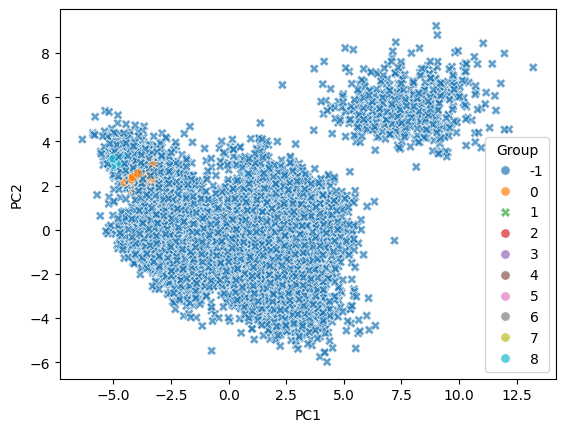

In [48]:
pca_dbscan = PCA(n_components=2)

x_dbscan_2d = pca_dbscan.fit_transform(x_dbscan)

# Create visualization dataframe
df_dbscan_viz = pd.DataFrame({
    'PC1': x_dbscan_2d[:, 0],
    'PC2': x_dbscan_2d[:, 1],
    'Group': dbscan_results
})

# plt.figure(figsize=(10, 7))

sb.scatterplot(
    data=df_dbscan_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='tab10',
    style=df_dbscan_viz['Group'] == -1,
    markers={True: 'X', False: 'o'},
    s=45,
    alpha=0.7
)


In [ ]:
# Measurements of the categories

df_cluster_analysis_3 = df.copy()
df_cluster_analysis_3['Cluster'] = dbscan_results
df_cluster_analysis_3.head()
df_cluster_analysis_3.groupby('Cluster')[df_cluster_analysis_3.columns].mean()

,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,Cluster
Cluster,,,,,,,,,,,,,,,,,,,
-1,6827.071027,53781.623142,862.461487,323.627227,202.634891,1.597988,0.757704,54519.941068,254.689034,0.748715,0.986952,0.869492,0.795702,0.006563,0.001678,0.636702,0.994895,NaN,-1.0
0,6321.217131,38228.906375,706.859837,244.987924,198.742564,1.232786,0.583079,38554.525896,220.502596,0.775809,0.991544,0.960510,0.900298,0.006421,0.002604,0.810662,0.998758,NaN,0.0
1,995.692308,44406.692308,788.409615,294.512200,192.611862,1.529076,0.756358,44924.923077,237.757723,0.778359,0.988463,0.897593,0.807339,0.006635,0.001739,0.651819,0.996545,NaN,1.0
2,1987.466667,28227.133333,621.768400,232.107726,155.128261,1.496350,0.743756,28554.333333,189.556094,0.716490,0.988544,0.917389,0.816691,0.008227,0.002258,0.667005,0.997950,NaN,2.0
3,3244.062500,37833.437500,720.871500,269.046156,179.356341,1.500153,0.745274,38215.750000,219.448904,0.717404,0.989998,0.914645,0.815683,0.007115,0.001943,0.665360,0.998016,NaN,3.0
4,7056.583333,39824.375000,738.537167,272.547527,186.419389,1.461832,0.729256,40232.291667,225.104738,0.799402,0.989866,0.917161,0.826034,0.006852,0.001969,0.682353,0.997360,NaN,4.0
5,6650.846154,41416.076923,758.778923,282.560431,187.145865,1.509922,0.749129,41869.538462,229.613796,0.716811,0.989176,0.903885,0.812640,0.006825,0.001836,0.660402,0.997048,NaN,5.0
6,9600.904762,34456.142857,691.415667,256.701707,171.342055,1.498340,0.744523,34864.190476,209.421363,0.713675,0.988301,0.905502,0.815834,0.007455,0.002037,0.665611,0.997159,NaN,6.0
7,10592.461538,34004.384615,686.484538,256.442740,169.146228,1.516339,0.751510,34399.384615,208.047203,0.780485,0.988519,0.906529,0.811295,0.007546,0.002017,0.658230,0.997911,NaN,7.0


DBSCAN with normalization and PCA

In [ ]:
pca_2 = PCA(n_components=.9)

x_dbscan_pca = ss.fit_transform(x)
x_dbscan_pca = pca_2.fit_transform(x_dbscan_pca)

dbs_2 = DBSCAN(eps=.5, min_samples=20, metric='euclidean', algorithm='auto')
dbscan_results_pca = dbs_2.fit_predict(x_dbscan_pca) 
# dbscan_results_pca # labels


array([-1,  0, -1, ..., -1,  0, -1], shape=(13611,))

In [64]:
x_valid_2 = x_dbscan_pca[(dbscan_results_pca != -1)]
valid_labels_2 = dbscan_results_pca[(dbscan_results_pca != -1)]
SS_within_2 = 0


for cluster in np.unique(valid_labels_2):
    cluster_data = x_valid_2[valid_labels_2 == cluster]

    SS_within_2 += np.sum(
        (cluster_data - cluster_data.mean(axis=0)) ** 2
    )

Data visualization and cluster traits

In [ ]:
# metrics and assesment
(dbscan_results == dbscan_results_pca).sum() # difference between the results 7337 matches
pca_2.explained_variance_ratio_.sum() # retained 90% of explained variance
explained_variance_2 = 1 - SS_within_2 / SS_total # 87%
silhouette_score(x_valid_2, valid_labels_2) # 37%
pd.DataFrame(dbscan_results_pca).value_counts() # category counts

<Axes: xlabel='PC1', ylabel='PC2'>

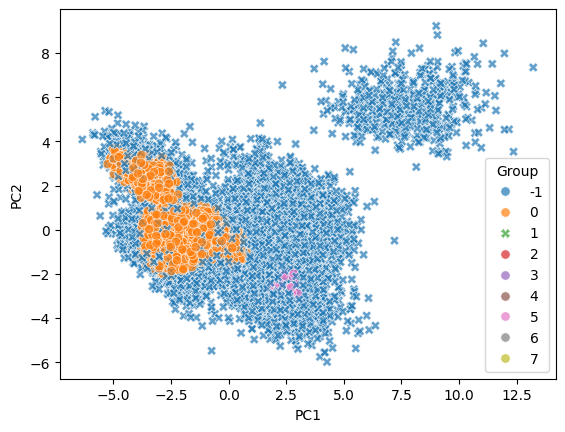

In [52]:
pca_dbscan2 = PCA(n_components=2)

x_dbscan_2d2 = pca_dbscan2.fit_transform(x_dbscan_pca)

# Create visualization dataframe
df_dbscan_viz = pd.DataFrame({
    'PC1': x_dbscan_2d2[:, 0],
    'PC2': x_dbscan_2d2[:, 1],
    'Group': dbscan_results_pca
})

# plt.figure(figsize=(10, 7))

sb.scatterplot(
    data=df_dbscan_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='tab10',
    style=df_dbscan_viz['Group'] == -1,
    markers={True: 'X', False: 'o'},
    s=45,
    alpha=0.7
)


In [62]:
# analyzing the traits of the clusters with PCA

df_cluster_analysis_4 = df.copy()
df_cluster_analysis_4['Cluster'] = dbscan_results_pca
df_cluster_analysis_4.head()
df_cluster_analysis_4.groupby('Cluster')[df_cluster_analysis_4.columns].mean()


,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,Cluster
Cluster,,,,,,,,,,,,,,,,,,,
-1,6807.142941,66126.265399,969.667211,366.143521,219.924099,1.679057,0.780227,67128.359912,281.962224,0.742074,0.985067,0.839231,0.776350,0.006139,0.001418,0.606689,0.993167,NaN,-1.0
0,6799.726445,38061.672788,720.899580,264.514366,182.874290,1.451364,0.710933,38470.043596,219.359171,0.759336,0.989356,0.915164,0.831843,0.007042,0.002094,0.693693,0.997188,NaN,0.0
1,1627.350000,76677.650000,1072.797500,410.899425,238.960898,1.720130,0.813273,77623.700000,312.416885,0.767547,0.987804,0.837499,0.760392,0.005362,0.001106,0.578278,0.994177,NaN,1.0
2,1649.703704,70162.592593,1030.157370,381.361416,235.657160,1.618770,0.785789,71284.666667,298.839506,0.761414,0.984281,0.831549,0.783769,0.005439,0.001267,0.614417,0.993877,NaN,2.0
3,1606.200000,48813.800000,868.539300,353.333899,176.604867,2.001886,0.866068,49426.300000,249.223434,0.735921,0.987591,0.812640,0.705305,0.007250,0.001106,0.497516,0.995490,NaN,3.0
4,1762.333333,54059.619048,926.810571,382.864926,180.462433,2.122366,0.881849,54654.047619,262.293896,0.689116,0.989129,0.790561,0.685115,0.007090,0.000964,0.469438,0.995853,NaN,4.0
5,8350.559859,55064.190141,929.717831,379.075774,185.751272,2.041735,0.871403,55736.390845,264.615931,0.719652,0.987913,0.799818,0.698228,0.006902,0.001012,0.487641,0.994669,NaN,5.0
6,5954.981308,73581.000000,1043.618187,399.138413,236.046810,1.691547,0.805882,74458.401869,306.008303,0.762145,0.988202,0.849142,0.766867,0.005429,0.001159,0.588218,0.994125,NaN,6.0
7,10708.371429,76403.257143,1071.531000,413.831908,236.929345,1.747003,0.819587,77360.428571,311.848910,0.758474,0.987621,0.836535,0.753697,0.005419,0.001079,0.568144,0.991985,NaN,7.0
